In [1]:
import pathlib

print("Current working directory:", pathlib.Path().resolve())

Current working directory: /Users/lms/Documents/Forschung/textClust_hpo


In [2]:
import pandas as pd
import os
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from moocore import hypervolume

from smac_hpo.evaluation.utils import build_results_csv, store_results_csv, load_results_csv, normalize, pareto_optimal_points 
from smac_hpo.evaluation.utils import COLORS, COLOR_PALETTE, ALGORITHM_ORDER, OLD_DATASETS, NEW_DATASETS, ALL_DATASETS, NUM_SEEDS, NUM_REPS
from smac_hpo.evaluation.utils import SINGLE_COLUMN_WIDTH, PANEL_HEIGHT, facet_aspect, set_publication_style
set_publication_style()

FIGURES_DIR = pathlib.Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
LATEX_DIR = pathlib.Path("latex")
LATEX_DIR.mkdir(parents=True, exist_ok=True )

In [3]:
HYPERPARAMETERS = {
    "FSD-SBERT": [
        "model",
        "threshold",
        "window",
        "batch_size"
    ],
    "textClust": [
        "clean_interval",
        "cluster_interval",
        "decay_rate",
        "min_num_mc",
        "term_fading",
        "adaptive_threshold",
        "sigma",
        "radius",
        "threshold_momentum",
        "use_heuristic",
        "time_gap",
        "min_weight"
    ],
    "embClust": [
        "model", 
        "clean_interval",
        "cluster_interval",
        "decay_rate",
        "min_num_mc",
        "adaptive_threshold",
        "sigma",
        "radius",
        "threshold_momentum",
        "use_heuristic",
        "time_gap",
        "min_weight"
    ],
}
HYPERPARAMETERS_FLATTENED = list(set(param for params in HYPERPARAMETERS.values() for param in params))

# Best trade-off configurations

In [4]:
full_opt_results_df = load_results_csv()
assert full_opt_results_df["dataset"].isin(ALL_DATASETS).all(), "Error: Some datasets in the results are not in the list of known datasets. Please check the dataset names."
assert full_opt_results_df["dataset"].isin(OLD_DATASETS).any(), "Error: No old datasets found in the results. Please check the dataset names."
assert full_opt_results_df["dataset"].isin(NEW_DATASETS).any(), "Error: No new datasets found in the results. Please check the dataset names."

In [5]:
# Config performance & default perfromance on new datasets
config_performance = full_opt_results_df[(full_opt_results_df["config_source"] == "full") & full_opt_results_df["dataset"].isin(NEW_DATASETS)].copy()
default_performance = full_opt_results_df[(full_opt_results_df["config_source"] == "default") & full_opt_results_df["dataset"].isin(NEW_DATASETS)].copy()

config_performance = (
    config_performance
    .groupby(["config_id", "algorithm"])[HYPERPARAMETERS_FLATTENED + ["adj_mutual_info_final", "avg_throughput"]]
    .agg(
    {
        **{param: "first" for param in HYPERPARAMETERS_FLATTENED},
        "adj_mutual_info_final": "mean",
        "avg_throughput": "mean",
    })
    .reset_index()
)

default_performance = (
    default_performance
    .groupby(["config_id", "algorithm"])[HYPERPARAMETERS_FLATTENED + ["adj_mutual_info_final", "avg_throughput"]]
    .agg(
    {
        **{param: "first" for param in HYPERPARAMETERS_FLATTENED},
        "adj_mutual_info_final": "mean",
        "avg_throughput": "mean",
    })
    .reset_index()
)

display(config_performance)

,config_id,algorithm,model,threshold_momentum,adaptive_threshold,batch_size,min_num_mc,radius,threshold,window,clean_interval,cluster_interval,use_heuristic,sigma,time_gap,decay_rate,min_weight,term_fading,adj_mutual_info_final,avg_throughput
0,FSD-SBERT_best_config_loo_none_seed_1.json[0],FSD-SBERT,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,8.0,NaN,NaN,0.500000,125.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.503487,181.214255
1,FSD-SBERT_best_config_loo_none_seed_1.json[1],FSD-SBERT,minishlab_4M,NaN,NaN,9.0,NaN,NaN,0.514959,116.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.355797,1599.526312
2,FSD-SBERT_best_config_loo_none_seed_1.json[2],FSD-SBERT,minishlab_4M,NaN,NaN,25.0,NaN,NaN,0.306805,59.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.240620,1774.569121
3,FSD-SBERT_best_config_loo_none_seed_1.json[3],FSD-SBERT,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,3.0,NaN,NaN,0.584279,76.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.530846,177.225932
4,FSD-SBERT_best_config_loo_none_seed_1.json[4],FSD-SBERT,minishlab_8M,NaN,NaN,29.0,NaN,NaN,0.586306,78.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.334936,1607.658261
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141,textClust_best_config_loo_none_seed_9.json[4],textClust,NaN,0.234695,1.0,NaN,2.0,NaN,NaN,NaN,400.0,4888.0,0.0,0.263364,NaN,0.000236,7.137730,1.0,0.446343,1186.348982
142,textClust_best_config_loo_none_seed_9.json[5],textClust,NaN,0.079436,1.0,NaN,9.0,NaN,NaN,NaN,227.0,4925.0,0.0,0.266890,NaN,0.021127,1.938501,1.0,0.480818,1502.891740
143,textClust_best_config_loo_none_seed_9.json[6],textClust,NaN,0.025919,1.0,NaN,2.0,NaN,NaN,NaN,114.0,4953.0,0.0,0.121910,NaN,0.011202,3.097142,0.0,0.481441,553.207406
144,textClust_best_config_loo_none_seed_9.json[7],textClust,NaN,0.010312,1.0,NaN,2.0,NaN,NaN,NaN,116.0,4957.0,0.0,0.145887,NaN,0.011370,4.407335,0.0,0.507487,588.014341


In [6]:
# Config performance & default perfromance on Trends-T
config_performance_trends_t = full_opt_results_df[(full_opt_results_df["config_source"] == "full") & (full_opt_results_df["dataset"]=="Trends-T")].copy()
default_performance_trends_t = full_opt_results_df[(full_opt_results_df["config_source"] == "default") & (full_opt_results_df["dataset"]=="Trends-T")].copy()

config_performance_trends_t = (
    config_performance_trends_t
    .groupby(["config_id", "algorithm"])[HYPERPARAMETERS_FLATTENED + ["adj_mutual_info_final", "avg_throughput"]]
    .agg(
    {
        **{param: "first" for param in HYPERPARAMETERS_FLATTENED},
        "adj_mutual_info_final": "mean",
        "avg_throughput": "mean",
    })
    .reset_index()
)

default_performance_trends_t = (
    default_performance_trends_t
    .groupby(["config_id", "algorithm"])[HYPERPARAMETERS_FLATTENED + ["adj_mutual_info_final", "avg_throughput"]]
    .agg(
    {
        **{param: "first" for param in HYPERPARAMETERS_FLATTENED},
        "adj_mutual_info_final": "mean",
        "avg_throughput": "mean",
    })
    .reset_index()
)

display(config_performance_trends_t)

,config_id,algorithm,model,threshold_momentum,adaptive_threshold,batch_size,min_num_mc,radius,threshold,window,clean_interval,cluster_interval,use_heuristic,sigma,time_gap,decay_rate,min_weight,term_fading,adj_mutual_info_final,avg_throughput
0,FSD-SBERT_best_config_loo_none_seed_1.json[0],FSD-SBERT,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,8.0,NaN,NaN,0.500000,125.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.509620,216.611047
1,FSD-SBERT_best_config_loo_none_seed_1.json[1],FSD-SBERT,minishlab_4M,NaN,NaN,9.0,NaN,NaN,0.514959,116.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.355275,1637.864408
2,FSD-SBERT_best_config_loo_none_seed_1.json[2],FSD-SBERT,minishlab_4M,NaN,NaN,25.0,NaN,NaN,0.306805,59.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.214632,1831.305544
3,FSD-SBERT_best_config_loo_none_seed_1.json[3],FSD-SBERT,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,3.0,NaN,NaN,0.584279,76.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.497949,211.953060
4,FSD-SBERT_best_config_loo_none_seed_1.json[4],FSD-SBERT,minishlab_8M,NaN,NaN,29.0,NaN,NaN,0.586306,78.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.491947,1721.205621
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141,textClust_best_config_loo_none_seed_9.json[4],textClust,NaN,0.234695,1.0,NaN,2.0,NaN,NaN,NaN,400.0,4888.0,0.0,0.263364,NaN,0.000236,7.137730,1.0,0.590203,1083.179284
142,textClust_best_config_loo_none_seed_9.json[5],textClust,NaN,0.079436,1.0,NaN,9.0,NaN,NaN,NaN,227.0,4925.0,0.0,0.266890,NaN,0.021127,1.938501,1.0,0.392981,1292.246403
143,textClust_best_config_loo_none_seed_9.json[6],textClust,NaN,0.025919,1.0,NaN,2.0,NaN,NaN,NaN,114.0,4953.0,0.0,0.121910,NaN,0.011202,3.097142,0.0,0.326982,87.148407
144,textClust_best_config_loo_none_seed_9.json[7],textClust,NaN,0.010312,1.0,NaN,2.0,NaN,NaN,NaN,116.0,4957.0,0.0,0.145887,NaN,0.011370,4.407335,0.0,0.498756,118.273403


In [7]:
# Best configs
df = config_performance.copy()

df_best_ami_idx = (df.copy()
                    .groupby("algorithm")
                    ["adj_mutual_info_final"]
                    .idxmax()
                    )

df_best_ami = (df.copy()
               .iloc[df_best_ami_idx, :])

df_best_tp_idx = (df.copy()
                [df["adj_mutual_info_final"] > 0.3]
                .groupby("algorithm")
                ["avg_throughput"]
                .idxmax()
                )

df_best_tp = (df.copy()
               .iloc[df_best_tp_idx, :])

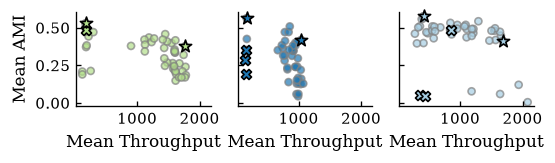

In [8]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Pareto fronts new datasets
df = config_performance.copy()

def draw_panel(data, default_performance, full_performance, best_ami, best_tp, **kwargs):
    ax = plt.gca()
    alg = data["algorithm"].iloc[0]
    
    best_ami_id = best_ami.loc[best_ami["algorithm"] == alg, "config_id"].values[0]
    best_tp_id = best_tp.loc[best_tp["algorithm"] == alg, "config_id"].values[0]
    
    best_ami = full_performance.loc[full_performance["config_id"] == best_ami_id, ["adj_mutual_info_final", "avg_throughput"]]
    best_tp = full_performance.loc[full_performance["config_id"] == best_tp_id, ["adj_mutual_info_final", "avg_throughput"]]
    
    default = default_performance[default_performance["algorithm"] == alg]
    
    color = COLORS[alg]
    sns.scatterplot(data, x="avg_throughput", y="adj_mutual_info_final", 
                    size=1,facecolor=color, linewidth=1, edgecolor="grey", alpha=0.7, ax=ax)
    
    plt.scatter(
        y=default["adj_mutual_info_final"],
        x=default["avg_throughput"],
        color=color,
        edgecolors="black",
        zorder=3,
        marker="X"
    )
    plt.scatter(
        y=best_ami["adj_mutual_info_final"],
        x=best_ami["avg_throughput"],
        color=color,
        edgecolors="black",
        zorder=3,
        marker="*",
        s=60,
        clip_on=False,
    )
    plt.scatter(
        y=best_tp["adj_mutual_info_final"],
        x=best_tp["avg_throughput"],
        color=color,
        edgecolors="black",
        zorder=3,
        marker="*",
        s=60,
        clip_on=False,
    )
    

g = sns.FacetGrid(df, col="algorithm", height=PANEL_HEIGHT*0.7, aspect=facet_aspect(len(ALGORITHM_ORDER),height=PANEL_HEIGHT*0.7))
g.map_dataframe(draw_panel, default_performance=default_performance, full_performance=df, 
                best_ami=df_best_ami, best_tp=df_best_tp)
g.set_titles(col_template="")
g.set_xlabels("Mean Throughput")
g.set_ylabels("Mean AMI")

legend_handles: list[Patch | Line2D] = [
    Patch(facecolor=COLORS[alg], label=alg, edgecolor="black") for alg in ALGORITHM_ORDER
]
legend_handles.append(
    Line2D(
        [],
        [],
        marker="*",
        linestyle="None",
        markerfacecolor="grey",
        markeredgecolor="black",
        label="Selected config.",
        markersize=8,
    )
)
legend_handles.append(
    Line2D(
        [],
        [],
        marker="X",
        linestyle="None",
        markerfacecolor="grey",
        markeredgecolor="black",
        label="Default config.",
        markersize=8,
    )
)
legend_fig = plt.figure()
legend_fig.legend(handles=legend_handles, loc="center", ncol=4)
legend_fig.savefig(
    FIGURES_DIR / "config_analysis_best_tradeoff_legend.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0,
)
plt.close(legend_fig)


g.figure.savefig(
    FIGURES_DIR / "config_analysis_best_tradeoff.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.1,
)

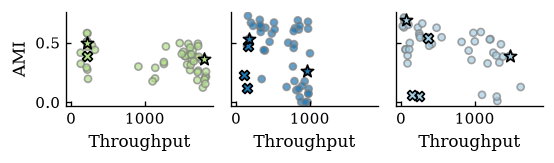

In [9]:
# Pareto fronts new datasets
df = config_performance_trends_t.copy()

g = sns.FacetGrid(df, col="algorithm", height=PANEL_HEIGHT*0.7, aspect=facet_aspect(len(ALGORITHM_ORDER),height=PANEL_HEIGHT*0.7))
g.map_dataframe(draw_panel, default_performance=default_performance_trends_t, full_performance=df, 
                best_ami=df_best_ami, best_tp=df_best_tp)
g.set_titles(col_template="")
g.set_xlabels("Throughput")
g.set_ylabels("AMI")

g.figure.savefig(
    FIGURES_DIR / "config_analysis_best_tradeoff_trends-t.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.1,
)


In [15]:
df_ami = df_best_ami.copy()
df_tp = df_best_tp.copy()

hyperparameter_order=[ 
    'adaptive_threshold',
    'sigma',
    'radius',
    'use_heuristic',
    'time_gap',
    'min_weight',
    'decay_rate',
    'threshold_momentum',
    'min_num_mc',
    'clean_interval', 'cluster_interval',
    'term_fading',
    'model', 'threshold', 'window', 'batch_size'
]

hyperparameter_types={
    'adaptive_threshold':bool,
    'sigma':float,
    'radius':float,
    'use_heuristic':bool,
    'time_gap':float,
    'min_weight':float,
    'decay_rate':float,
    'threshold_momentum':float,
    'min_num_mc':int,
    'clean_interval':int, 
    'cluster_interval':int,
    'term_fading':bool,
    'model':str, 
    'threshold':float, 
    'window':int, 
    'batch_size':int

}

hyperparameter_names={
    'adaptive_threshold':"Adaptive Threshold",
    'sigma':"Sigma",
    'radius':"Radius",
    'use_heuristic':"Min. Weight Heuristic",
    'time_gap':"Time Gap",
    'min_weight':"Min. Weight",
    'decay_rate':"Decay Rate",
    'threshold_momentum':"Thresh. Momentum",
    'min_num_mc':"Min. \\#Microclusters",
    'clean_interval':"Clean Interval", 
    'cluster_interval':"Cluster Interval",
    'term_fading':"Term Fading",
    'model':"Emb. model", 
    'threshold':"Threshold", 
    'window':"Window Size", 
    'batch_size':"Batch Size"
}

str_renames = {
    "sentence_transformers_all_MiniLM_L6_v2": "ST",
    "NeuML" : "NML",
    "minishlab_4M" : "ML"
}


def prep_dataset(df):
    df = df.drop(columns=['config_id'])
    
    bool_cols = [n for n,t in hyperparameter_types.items() if t == bool]
    int_cols = [n for n,t in hyperparameter_types.items() if t == int]
    float_cols = [n for n,t in hyperparameter_types.items() if t == float]
    
    for col in bool_cols:
        df[col] = df[col].map({1.0: "on", 0.0: "off"}).fillna("-")
        
    for col in int_cols:
        df[col] = df[col].astype("Int64")
        
    for col in float_cols:
        df[col] = df[col].map(
            lambda value: f"{value:.4f}" if pd.notna(value) else value
        )
        
    df = df.replace(str_renames)
    
    df.index = df["algorithm"]
    df = df.drop(columns=["algorithm"]).transpose()

    df = df.fillna("-")
    df = df.loc[hyperparameter_order, :]
    df = df.rename(index=hyperparameter_names)
    return df

pretty_ami = prep_dataset(df_ami)
pretty_tp = prep_dataset(df_tp)

pretty_combined = pd.concat({"Best AMI": pretty_ami, "Best Throughput": pretty_tp}, axis=1)
pretty_combined.columns = pretty_combined.columns.set_names([None, None])
display(pretty_combined)

latex_table = pretty_combined.style.to_latex(
    column_format="lcccccc", multicol_align="c",
    label="tab:best_configs_selection",
    caption="Best trade-off configurations per algorithm. '-' indicates that a hyperparameter is not applicable. 'ST' and 'ML' stand for sentence-transformers/all-MiniLM-L6-v2~\\cite{sentence_transformers_minilm} and minishlab/potion-base-4M~\\cite{minishlab2024model2vec}, respectively")

latex_table = latex_table.replace(
    "\\begin{tabular}",
    "\\resizebox{\\columnwidth}{!}{%\n\\begin{tabular}",
    1,
)
latex_table = latex_table.replace(
    "\\end{tabular}",
    "\\end{tabular}%\n}",
    1,
)

print(latex_table)
(LATEX_DIR / "best_configurations.tex").write_text(
    latex_table,
    encoding="utf-8",
)

Best AMI                    Best Throughput           \
                      FSD-SBERT embClust textClust       FSD-SBERT embClust   
Adaptive Threshold            -       on        on               -       on   
Sigma                         -   1.4982    0.3512               -   0.9023   
Radius                        -        -         -               -        -   
Min. Weight Heuristic         -      off       off               -      off   
Time Gap                      -        -         -               -        -   
Min. Weight                   -   5.9549    0.3283               -   9.6353   
Decay Rate                    -   0.0088    0.0092               -   0.0083   
Thresh. Momentum              -   0.1168    0.5580               -   0.5332   
Min. \#Microclusters          -        1         3               -        1   
Clean Interval                -      300       353               -      389   
Cluster Interval              -      553      2463               -     2734   
Term Fading                   -        -       off               -        -   
Emb. model                   ST       ST         -              ML       ML   
Threshold                0.5843        -         -          0.4212        -   
Window Size                  76        -         -              60        -   
Batch Size                    3        -         -              25        -   

                                 
                      textClust  
Adaptive Threshold           on  
Sigma                    0.8177  
Radius                        -  
Min. Weight Heuristic       off  
Time Gap                      -  
Min. Weight              2.7418  
Decay Rate               0.0090  
Thresh. Momentum         0.1719  
Min. \#Microclusters         11  
Clean Interval               69  
Cluster Interval           2552  
Term Fading                  on  
Emb. model                    -  
Threshold                     -  
Window Size                   -  
Batch Size                    -

\begin{table}
\caption{Best trade-off configurations per algorithm. '-' indicates that a hyperparameter is not applicable. 'ST' and 'ML' stand for sentence-transformers/all-MiniLM-L6-v2~\cite{sentence_transformers_minilm} and minishlab/potion-base-4M~\cite{minishlab2024model2vec}, respectively}
\label{tab:best_configs_selection}
\resizebox{\columnwidth}{!}{%
\begin{tabular}{lcccccc}
 & \multicolumn{3}{c}{Best AMI} & \multicolumn{3}{c}{Best Throughput} \\
 & FSD-SBERT & embClust & textClust & FSD-SBERT & embClust & textClust \\
Adaptive Threshold & - & on & on & - & on & on \\
Sigma & - & 1.4982 & 0.3512 & - & 0.9023 & 0.8177 \\
Radius & - & - & - & - & - & - \\
Min. Weight Heuristic & - & off & off & - & off & off \\
Time Gap & - & - & - & - & - & - \\
Min. Weight & - & 5.9549 & 0.3283 & - & 9.6353 & 2.7418 \\
Decay Rate & - & 0.0088 & 0.0092 & - & 0.0083 & 0.0090 \\
Thresh. Momentum & - & 0.1168 & 0.5580 & - & 0.5332 & 0.1719 \\
Min. \#Microclusters & - & 1 & 3 & - & 1 & 11 \\
Clean I

1337